# Comparaison SGD / RMSProp / Adam sur un MLP (MNIST)

Sensibilité au learning rate : même démarche que le TP4. On construit le MLP une fois, puis on le passe au `Trainer` avec l'optimiseur de notre choix.

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

from training_toolbox import Trainer, accuracy

**I) Paramètres**

In [2]:
BATCH_SIZE = 128
OPTIMISEURS = {
    "SGD": torch.optim.SGD,
    "RMSProp": torch.optim.RMSprop,
    "Adam": torch.optim.Adam,
}
GRILLE_LR = [1e-10, 1e-8, 1e-5, 1e-3, 1e-2, 1e-1, 1.0]
EPOCHS_LR = 5      # passages complets sur le jeu d'entraînement
N_SEEDS_LR = 2     # répétitions (moyenne des précisions)

**II) Données** (comme le TP4, avec la normalisation MNIST en plus)

Validation = les 10 000 dernières images du train (le test n'est pas utilisé pour choisir le lr).

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
    transforms.Lambda(lambda x: x.view(-1)),
])

mnist_train = datasets.MNIST(root="./data", train=True, download=True, transform=transform)

train_loader = DataLoader(Subset(mnist_train, range(50000)), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(Subset(mnist_train, range(50000, 60000)), batch_size=1000, shuffle=False)

100%|██████████| 9.91M/9.91M [00:01<00:00, 8.97MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 313kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.76MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.46MB/s]


**III) Le MLP** (identique à ton modèle actuel, écrit comme au TP4)

In [4]:
class MulticlassMLP(nn.Module):
    def __init__(self, n_features=784, hidden_1=128, hidden_2=64, n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden_1),
            nn.ReLU(),
            nn.Linear(hidden_1, hidden_2),
            nn.ReLU(),
            nn.Linear(hidden_2, n_classes),
        )

    def forward(self, x):
        return self.net(x)

**IV) Entraînement avec un optimiseur passé en variable**

In [8]:
def run(optimizer_cls, lr, epochs, seed, train_loader=train_loader, val_loader=val_loader):
    torch.manual_seed(seed)
    model = MulticlassMLP()
    optimizer = optimizer_cls(model.parameters(), lr=lr)
    trainer = Trainer(model, optimizer, nn.CrossEntropyLoss(), metrics={"acc": accuracy})
    return trainer.fit(train_loader, val_loader, epochs=epochs)

**V) Expérience : sensibilité au learning rate**

In [6]:
acc = {nom: [] for nom in OPTIMISEURS}

for nom, opt_cls in OPTIMISEURS.items():
    for lr in GRILLE_LR:
        a = np.mean([run(opt_cls, lr, EPOCHS_LR, seed)["val_acc"][-1] for seed in range(N_SEEDS_LR)])
        acc[nom].append(a)
        print(f"{nom:8s} lr={lr:<8g} -> précision validation = {a:.4f}")

best_lr = {nom: GRILLE_LR[int(np.argmax(acc[nom]))] for nom in OPTIMISEURS}
print("Meilleur lr :", best_lr)

Epoch 1/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3060 - val_acc: 0.1068
Epoch 2/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3060 - val_acc: 0.1068
Epoch 3/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3060 - val_acc: 0.1068
Epoch 4/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3060 - val_acc: 0.1068
Epoch 5/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3060 - val_acc: 0.1068
Epoch 1/5 - train_loss: 2.3012 - train_acc: 0.1092 - val_loss: 2.3020 - val_acc: 0.1081
Epoch 2/5 - train_loss: 2.3012 - train_acc: 0.1092 - val_loss: 2.3020 - val_acc: 0.1081
Epoch 3/5 - train_loss: 2.3012 - train_acc: 0.1092 - val_loss: 2.3020 - val_acc: 0.1081
Epoch 4/5 - train_loss: 2.3012 - train_acc: 0.1092 - val_loss: 2.3020 - val_acc: 0.1081
Epoch 5/5 - train_loss: 2.3012 - train_acc: 0.1092 - val_loss: 2.3020 - val_acc: 0.1081
SGD      lr=1e-10    -> précision validation = 0.1075
Epoch 1/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3

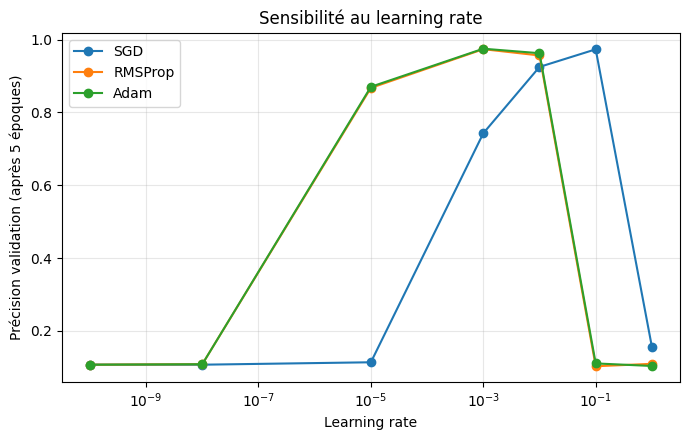

In [7]:
plt.figure(figsize=(7, 4.5))
for nom in OPTIMISEURS:
    plt.plot(GRILLE_LR, acc[nom], marker="o", label=nom)
plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel(f"Précision validation (après {EPOCHS_LR} époques)")
plt.title("Sensibilité au learning rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("exp1_sensibilite_lr.png", dpi=150)
plt.show()

Epoch 1/10 - train_loss: 0.4093 - train_acc: 0.8792 - val_loss: 0.2078 - val_acc: 0.9374
Epoch 2/10 - train_loss: 0.1558 - train_acc: 0.9540 - val_loss: 0.1250 - val_acc: 0.9623
Epoch 3/10 - train_loss: 0.1082 - train_acc: 0.9671 - val_loss: 0.0976 - val_acc: 0.9697
Epoch 4/10 - train_loss: 0.0825 - train_acc: 0.9751 - val_loss: 0.0803 - val_acc: 0.9754
Epoch 5/10 - train_loss: 0.0645 - train_acc: 0.9805 - val_loss: 0.0815 - val_acc: 0.9757
Epoch 6/10 - train_loss: 0.0523 - train_acc: 0.9842 - val_loss: 0.0796 - val_acc: 0.9745
Epoch 7/10 - train_loss: 0.0427 - train_acc: 0.9879 - val_loss: 0.0671 - val_acc: 0.9786
Epoch 8/10 - train_loss: 0.0350 - train_acc: 0.9894 - val_loss: 0.0696 - val_acc: 0.9789
Epoch 9/10 - train_loss: 0.0292 - train_acc: 0.9915 - val_loss: 0.0802 - val_acc: 0.9750
Epoch 10/10 - train_loss: 0.0243 - train_acc: 0.9929 - val_loss: 0.0692 - val_acc: 0.9805
Epoch 1/10 - train_loss: 0.3963 - train_acc: 0.8818 - val_loss: 0.1939 - val_acc: 0.9419
Epoch 2/10 - train_l

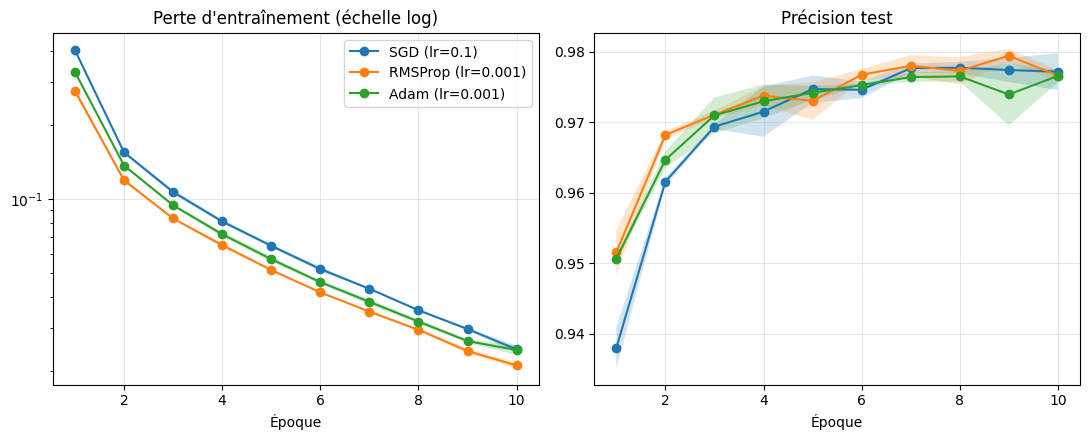

In [9]:
EPOCHS = 10
N_SEEDS = 3

# Entraînement sur les 60 000 images, évaluation sur le test (10 000)
mnist_test = datasets.MNIST(root="./data", train=False, download=True, transform=transform)
full_train_loader = DataLoader(mnist_train, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(mnist_test, batch_size=1000, shuffle=False)

results = {}
for nom, opt_cls in OPTIMISEURS.items():
    runs = [run(opt_cls, best_lr[nom], EPOCHS, seed, full_train_loader, test_loader)
            for seed in range(N_SEEDS)]
    results[nom] = {k: np.array([r[k] for r in runs]) for k in ("train_loss", "val_acc")}
    r = results[nom]
    print(f"{nom:8s} lr={best_lr[nom]:<6g} | précision test finale = "
          f"{r['val_acc'][:, -1].mean():.4f} +/- {r['val_acc'][:, -1].std():.4f}")

epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
panneaux = [("train_loss", "Perte d'entraînement (échelle log)"),
            ("val_acc", "Précision test")]
for ax, (key, titre) in zip(axes, panneaux):
    for nom in OPTIMISEURS:
        m, s = results[nom][key].mean(0), results[nom][key].std(0)
        ax.plot(epochs, m, marker="o", label=f"{nom} (lr={best_lr[nom]:g})")
        ax.fill_between(epochs, m - s, m + s, alpha=0.2)
    ax.set_title(titre)
    ax.set_xlabel("Époque")
    ax.grid(alpha=0.3)
axes[0].set_yscale("log")
axes[0].legend()
plt.tight_layout()
plt.savefig("exp2_convergence.png", dpi=150)
plt.show()

La **perte d’entraînement** est mesurée uniquement sur les données d’entraînement. Elle reflète à la fois les erreurs de classification du modèle et le degré de confiance avec lequel il prédit. Les optimiseurs ont pour but de minimiser cette perte en ajustant les poids du réseau.

Ici, la perte diminue nettement au fil des époques pour les trois méthodes, sans oscillation ni divergence. RMSProp reste légèrement en dessous des deux autres sur toute la durée, Adam est juste derrière, et SGD est le plus lent au départ. L’écart se réduit avec les époques : à l’époque 10, SGD et Adam sont presque confondus. Les différences entre les trois méthodes sont donc faibles.

Les trois optimiseurs parviennent ainsi à minimiser efficacement la perte sur les données d’entraînement. Reste à vérifier, avec la précision de test, que cet apprentissage se généralise à des données nouvelles.

La **précision de test** est le critère de performance du modèle. Ici, on a utilisé l'accuracy. Il permet de connaître la proportion d’images de test correctement classées. Elle est calculée sur des données que le réseau n’a pas utilisées pour apprendre, ce qui permet de vérifier sa capacité à généraliser.  
    
À l’époque 1, RMSProp et Adam sont à ~0,95 contre ~0,94 pour SGD. SGD les rattrape vers l’époque 3-4.  
À la fin, les trois sont autour de 0,977. Les écarts entre méthodes sont du même ordre que les bandes d’erreur (Adam : 0,9766 ± 0,0009), donc on ne peut pas désigner un gagnant sur la qualité finale.  
  
Les bandes d’Adam et de RMSProp sont un peu plus larges sur les dernières époques, avec un creux visible pour Adam à l’époque 9. Avec seulement 3 seeds, je lirais ça comme du bruit plutôt que comme de l’instabilité.

Ces 2 graphiques nous renseignent également sur la question d'un éventuel **sur-apprentissage** du modèle.  
Effectivement, on remarque que la perte d’entraînement continue de baisser, mais la précision test stagne dès l’époque 6-7. On peut donc conclure que continuer l'entraînement n'apporterait plus rien, voire commencerait à faire sur-apprendre le modèle.

**Conclusion** : Sur ce petit MLP, les méthodes adaptatives convergent plus vite au début, mais SGD bien réglé atteint la même qualité finale. L’avantage d’Adam et RMSProp est donc surtout la robustesse au choix du lr et la rapidité initiale, pas un meilleur minimum.

A faire la prochaine fois : stabilité et qualité du minimum